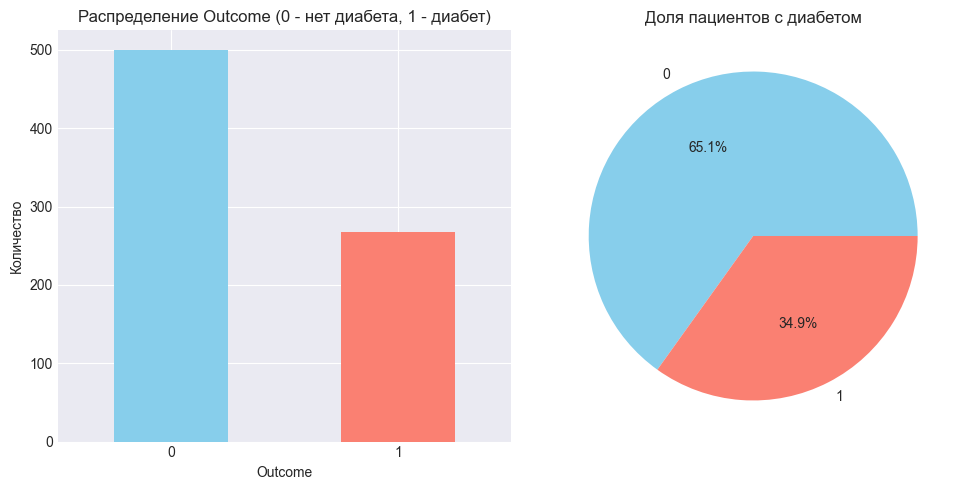

Пациентов без диабета: 500 (65.1%)
Пациентов с диабетом: 268 (34.9%)


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

df = pd.read_csv('diabetes.csv')
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
df['Outcome'].value_counts().plot(kind='bar', color=['skyblue', 'salmon'])
plt.title('Распределение Outcome (0 - нет диабета, 1 - диабет)')
plt.xlabel('Outcome')
plt.ylabel('Количество')
plt.xticks(rotation=0)

plt.subplot(1, 2, 2)
df['Outcome'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['skyblue', 'salmon'])
plt.title('Доля пациентов с диабетом')
plt.ylabel('')

plt.tight_layout()
plt.show()

print(f"Пациентов без диабета: {df[df['Outcome']==0].shape[0]} ({df[df['Outcome']==0].shape[0]/df.shape[0]*100:.1f}%)")
print(f"Пациентов с диабетом: {df[df['Outcome']==1].shape[0]} ({df[df['Outcome']==1].shape[0]/df.shape[0]*100:.1f}%)")


Пропуски после замены нулей: 652
Заполнено Glucose: 117.00
Заполнено BloodPressure: 72.00
Заполнено SkinThickness: 29.00
Заполнено Insulin: 125.00
Заполнено BMI: 32.30

Пропуски после заполнения: 0


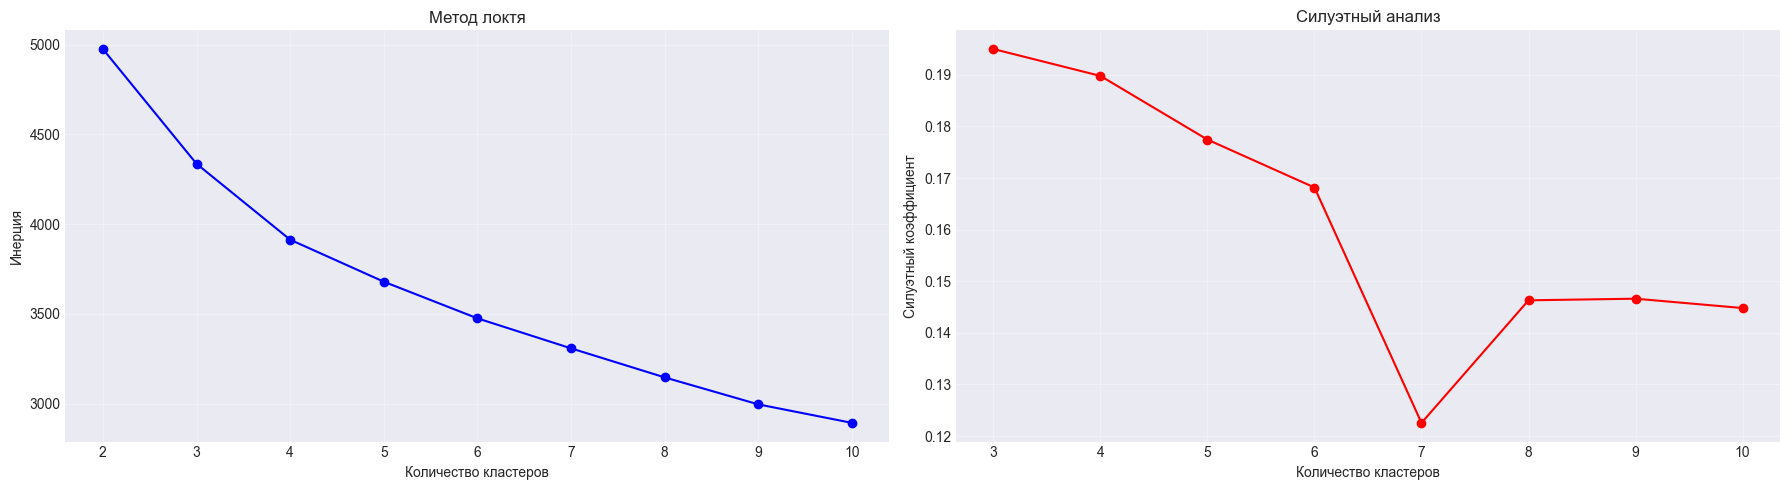

Оптимальное количество кластеров по методу локтя: 4
Оптимальное количество кластеров по силуэтному анализу: 3


In [3]:
X = df.drop('Outcome', axis=1)
y = df['Outcome']


features_with_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
for feature in features_with_zeros:
    X[feature] = X[feature].replace(0, np.nan)

print(f"\nПропуски после замены нулей: {X.isnull().sum().sum()}")

for feature in X.columns:
    if X[feature].isnull().sum() > 0:
        median_value = X[feature].median()
        X[feature] = X[feature].fillna(median_value)
        print(f"Заполнено {feature}: {median_value:.2f}")

print(f"\nПропуски после заполнения: {X.isnull().sum().sum()}")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

pca = PCA()
pca.fit(X_scaled)

inertias = []
silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)
    
    if k > 1: 
        silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))
    else:
        silhouette_scores.append(0)


fig, axes = plt.subplots(1, 2, figsize=(18, 5))

axes[0].plot(list(k_range), inertias, 'bo-')
axes[0].set_xlabel('Количество кластеров')
axes[0].set_ylabel('Инерция')
axes[0].set_title('Метод локтя')
axes[0].grid(True, alpha=0.3)

axes[1].plot(list(k_range)[1:], silhouette_scores[1:], 'ro-')
axes[1].set_xlabel('Количество кластеров')
axes[1].set_ylabel('Силуэтный коэффициент')
axes[1].set_title('Силуэтный анализ')
axes[1].grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

optimal_k_inertia = 4
optimal_k_silhouette = list(k_range)[np.argmax(silhouette_scores[1:]) + 1]
print(f"Оптимальное количество кластеров по методу локтя: {optimal_k_inertia}")
print(f"Оптимальное количество кластеров по силуэтному анализу: {optimal_k_silhouette}")

Объясненная дисперсия 3 компонент: 0.615


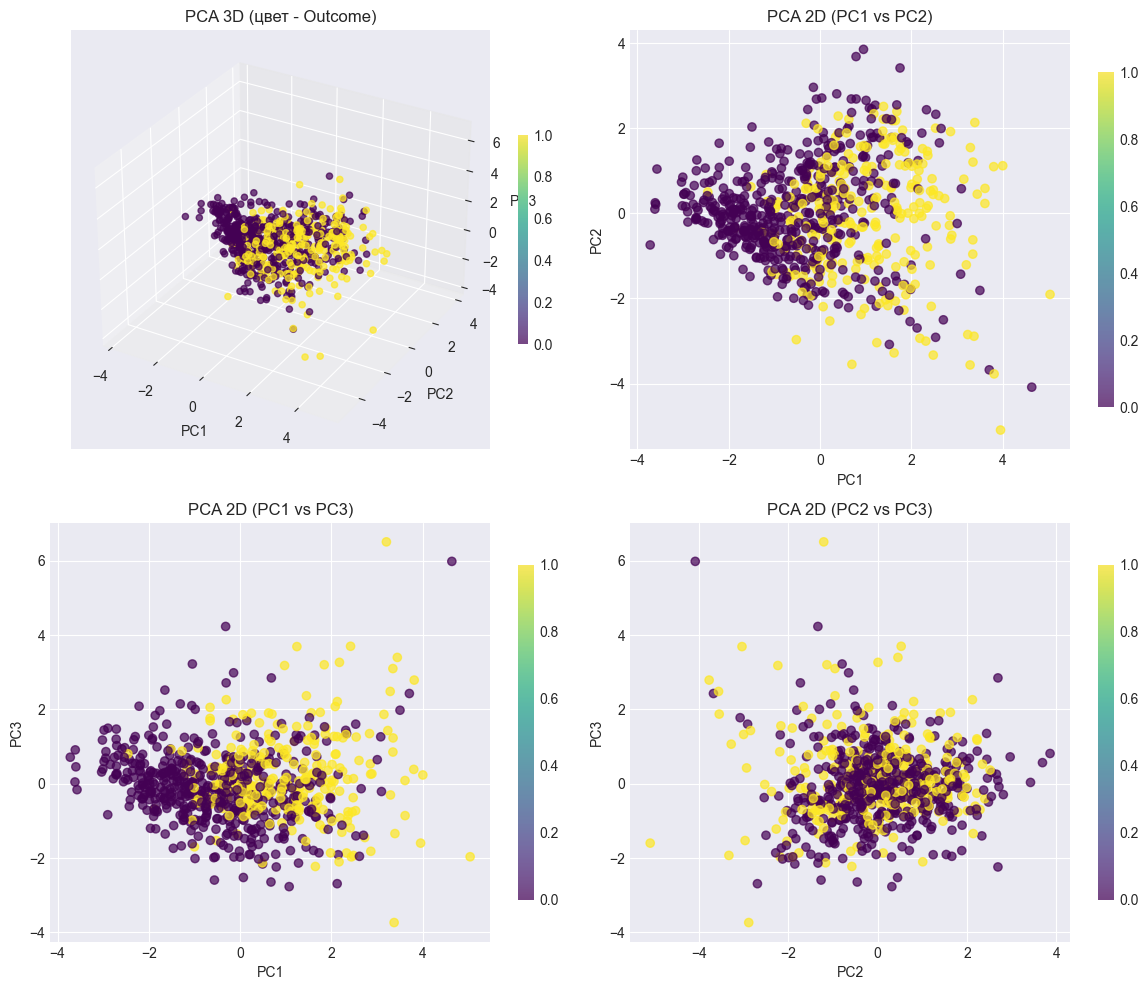

In [4]:
pca_3d = PCA(n_components=3)
X_pca_3d = pca_3d.fit_transform(X_scaled)

print(f"Объясненная дисперсия 3 компонент: {sum(pca_3d.explained_variance_ratio_):.3f}")

fig = plt.figure(figsize=(12, 10))

ax = fig.add_subplot(221, projection='3d')
scatter = ax.scatter(X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2], 
                     c=y, cmap='viridis', alpha=0.7)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.set_title('PCA 3D (цвет - Outcome)')
plt.colorbar(scatter, ax=ax, shrink=0.5)

ax2 = fig.add_subplot(222)
scatter2 = ax2.scatter(X_pca_3d[:, 0], X_pca_3d[:, 1], c=y, cmap='viridis', alpha=0.7)
ax2.set_xlabel('PC1')
ax2.set_ylabel('PC2')
ax2.set_title('PCA 2D (PC1 vs PC2)')
plt.colorbar(scatter2, ax=ax2, shrink=0.8)

ax3 = fig.add_subplot(223)
scatter3 = ax3.scatter(X_pca_3d[:, 0], X_pca_3d[:, 2], c=y, cmap='viridis', alpha=0.7)
ax3.set_xlabel('PC1')
ax3.set_ylabel('PC3')
ax3.set_title('PCA 2D (PC1 vs PC3)')
plt.colorbar(scatter3, ax=ax3, shrink=0.8)

ax4 = fig.add_subplot(224)
scatter4 = ax4.scatter(X_pca_3d[:, 1], X_pca_3d[:, 2], c=y, cmap='viridis', alpha=0.7)
ax4.set_xlabel('PC2')
ax4.set_ylabel('PC3')
ax4.set_title('PCA 2D (PC2 vs PC3)')
plt.colorbar(scatter4, ax=ax4, shrink=0.8)

plt.tight_layout()
plt.show()

Размеры кластеров K-Means:
Cluster_KMeans
0    184
1    309
2    233
3     42
Name: count, dtype: int64


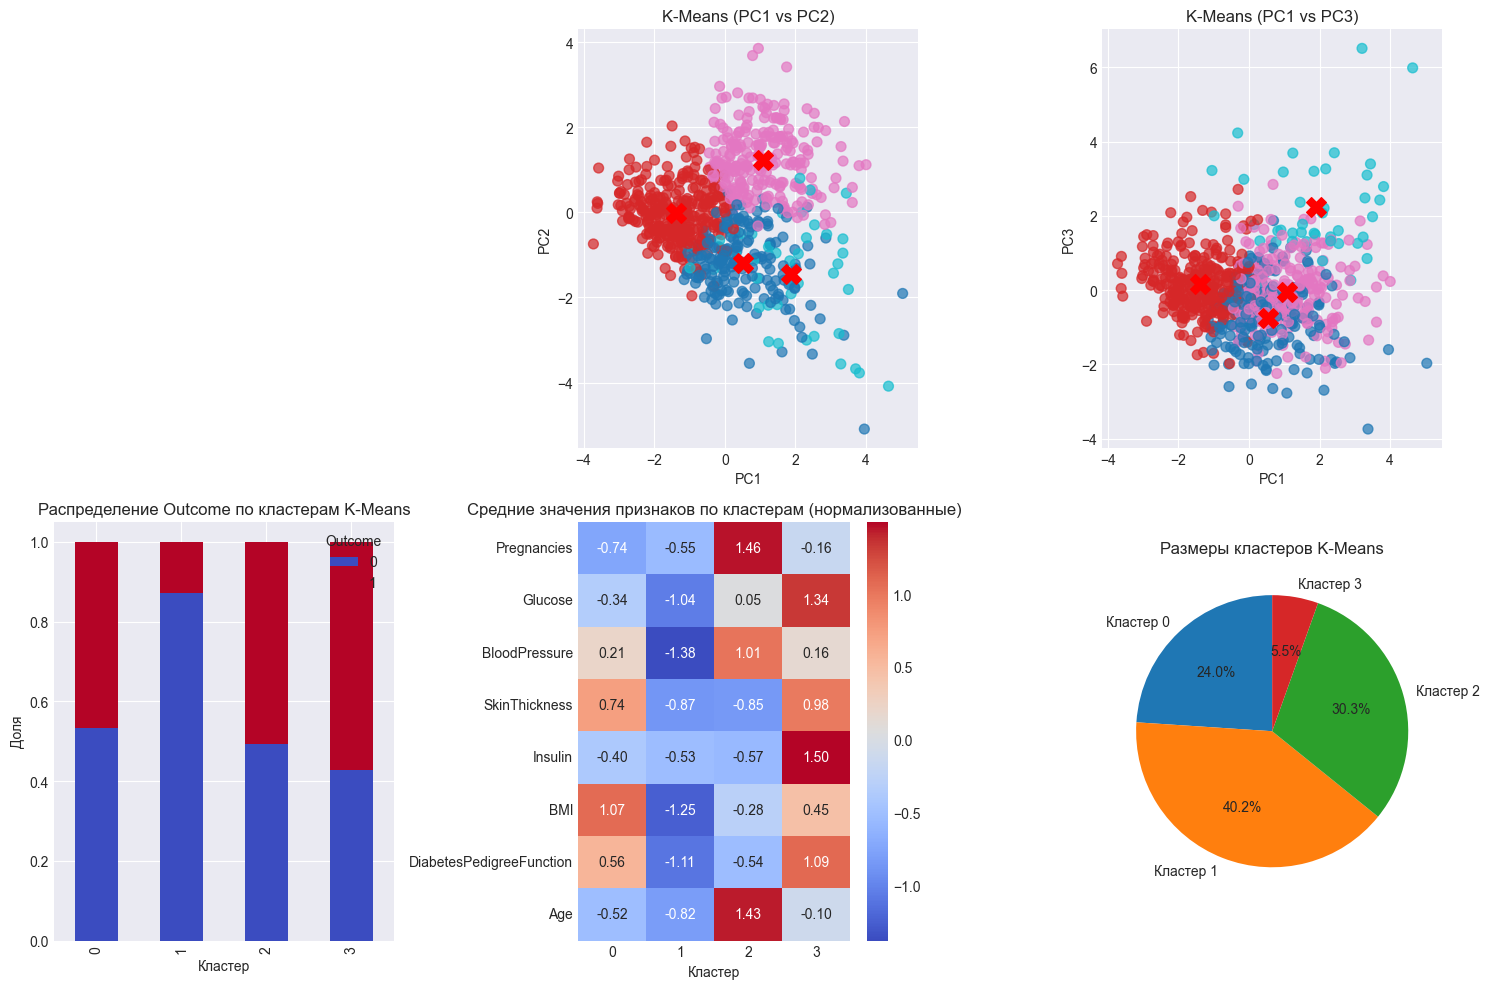

Характеристики кластеров K-Means:

Кластер 0
Размер: 184 пациентов (24.0%)
Доля пациентов с диабетом: 46.7%
Средние значения ключевых признаков:
  Glucose: 122.64
  BMI: 39.21
  Age: 28.80
  Insulin: 79.51

Кластер 1
Размер: 309 пациентов (40.2%)
Доля пациентов с диабетом: 12.9%
Средние значения ключевых признаков:
  Glucose: 106.08
  BMI: 27.06
  Age: 26.11
  Insulin: 56.72

Кластер 2
Размер: 233 пациентов (30.3%)
Доля пациентов с диабетом: 50.6%
Средние значения ключевых признаков:
  Glucose: 131.74
  BMI: 32.12
  Age: 46.33
  Insulin: 48.82

Кластер 3
Размер: 42 пациентов (5.5%)
Доля пациентов с диабетом: 57.1%
Средние значения ключевых признаков:
  Glucose: 162.12
  BMI: 35.97
  Age: 32.52
  Insulin: 422.69


In [ ]:
optimal_k = 4 

kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

df_kmeans = df.copy()
df_kmeans['Cluster_KMeans'] = kmeans_labels
X_scaled_df['Cluster_KMeans'] = kmeans_labels

print(f"Размеры кластеров K-Means:")
print(df_kmeans['Cluster_KMeans'].value_counts().sort_index())

fig = plt.figure(figsize=(15, 10))

centroids_pca = pca_3d.transform(kmeans.cluster_centers_)

ax2 = fig.add_subplot(232)
scatter2 = ax2.scatter(X_pca_3d[:, 0], X_pca_3d[:, 1], c=kmeans_labels, cmap='tab10', alpha=0.7, s=50)
ax2.scatter(centroids_pca[:, 0], centroids_pca[:, 1], c='red', marker='X', s=200, alpha=1)
ax2.set_xlabel('PC1')
ax2.set_ylabel('PC2')
ax2.set_title('K-Means (PC1 vs PC2)')

ax3 = fig.add_subplot(233)
scatter3 = ax3.scatter(X_pca_3d[:, 0], X_pca_3d[:, 2], c=kmeans_labels, cmap='tab10', alpha=0.7, s=50)
ax3.scatter(centroids_pca[:, 0], centroids_pca[:, 2], c='red', marker='X', s=200, alpha=1)
ax3.set_xlabel('PC1')
ax3.set_ylabel('PC3')
ax3.set_title('K-Means (PC1 vs PC3)')

ax4 = fig.add_subplot(234)
cluster_outcome = pd.crosstab(df_kmeans['Cluster_KMeans'], df_kmeans['Outcome'], 
                              normalize='index')
cluster_outcome.plot(kind='bar', stacked=True, ax=ax4, colormap='coolwarm')
ax4.set_xlabel('Кластер')
ax4.set_ylabel('Доля')
ax4.set_title('Распределение Outcome по кластерам K-Means')
ax4.legend(title='Outcome', loc='upper right')

ax5 = fig.add_subplot(235)
cluster_means = df_kmeans.groupby('Cluster_KMeans').mean().drop('Outcome', axis=1)
cluster_means_normalized = (cluster_means - cluster_means.mean()) / cluster_means.std()
sns.heatmap(cluster_means_normalized.T, annot=True, fmt='.2f', cmap='coolwarm', ax=ax5)
ax5.set_title('Средние значения признаков по кластерам (нормализованные)')
ax5.set_xlabel('Кластер')

ax6 = fig.add_subplot(236)
sizes = df_kmeans['Cluster_KMeans'].value_counts().sort_index()
colors = plt.cm.tab10(range(optimal_k))
ax6.pie(sizes, labels=[f'Кластер {i}' for i in sizes.index], 
        autopct='%1.1f%%', colors=colors, startangle=90)
ax6.set_title('Размеры кластеров K-Means')

plt.tight_layout()
plt.show()


print("Характеристики кластеров K-Means:")
for cluster in range(optimal_k):
    print(f"\nКластер {cluster}")
    print(f"Размер: {sum(kmeans_labels == cluster)} пациентов ({sum(kmeans_labels == cluster)/len(kmeans_labels)*100:.1f}%)")
    
    cluster_data = df[df_kmeans['Cluster_KMeans'] == cluster]
    print(f"Доля пациентов с диабетом: {cluster_data['Outcome'].mean()*100:.1f}%")
    
    key_features = ['Glucose', 'BMI', 'Age', 'Insulin']
    print("Средние значения ключевых признаков:")
    for feature in key_features:
        print(f"  {feature}: {cluster_data[feature].mean():.2f}")

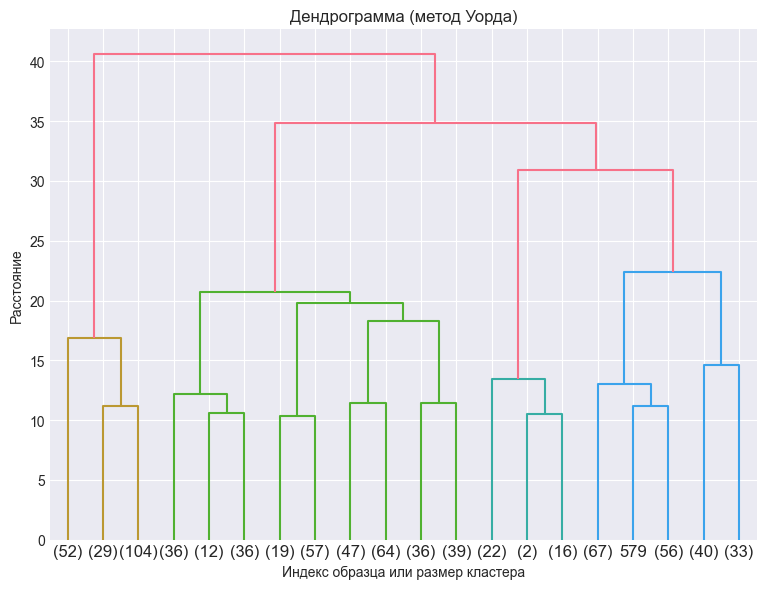

Версия scikit-learn: 1.7.2
Размеры кластеров иерархической кластеризации:
Cluster_Hierarchical
0    197
1    185
2    346
3     40
Name: count, dtype: int64


In [ ]:
plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
Z = linkage(X_scaled, method='ward', metric='euclidean')
dendrogram(Z, truncate_mode='lastp', p=20, show_leaf_counts=True)
plt.title('Дендрограмма (метод Уорда)')
plt.xlabel('Индекс образца или размер кластера')
plt.ylabel('Расстояние')

plt.tight_layout()
plt.show()

hierarchical_k = 4  
import sklearn
print(f"Версия scikit-learn: {sklearn.__version__}")

hierarchical = AgglomerativeClustering(n_clusters=hierarchical_k, 
                                    metric='euclidean', 
                                    linkage='ward')

hierarchical_labels = hierarchical.fit_predict(X_scaled)

df_hierarchical = df.copy()
df_hierarchical['Cluster_Hierarchical'] = hierarchical_labels
X_scaled_df['Cluster_Hierarchical'] = hierarchical_labels

print(f"Размеры кластеров иерархической кластеризации:")
print(df_hierarchical['Cluster_Hierarchical'].value_counts().sort_index())

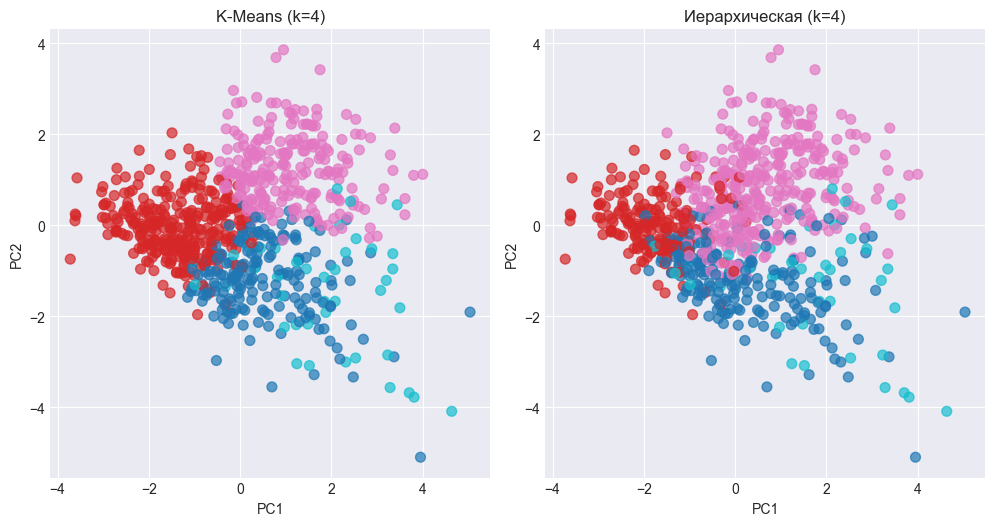

In [ ]:
fig = plt.figure(figsize=(15, 10))

ax1 = fig.add_subplot(231)
scatter1 = ax1.scatter(X_pca_3d[:, 0], X_pca_3d[:, 1], c=kmeans_labels, cmap='tab10', alpha=0.7, s=50)
ax1.set_xlabel('PC1')
ax1.set_ylabel('PC2')
ax1.set_title(f'K-Means (k={optimal_k})')

ax2 = fig.add_subplot(232)
scatter2 = ax2.scatter(X_pca_3d[:, 0], X_pca_3d[:, 1], c=hierarchical_labels, cmap='tab10', alpha=0.7, s=50)
ax2.set_xlabel('PC1')
ax2.set_ylabel('PC2')
ax2.set_title(f'Иерархическая (k={hierarchical_k})')


plt.tight_layout()
plt.show()

In [ ]:
print("Оценка качества кластеризации:")

print("\nK-Means кластеризация:")
print(f"Инерция: {kmeans.inertia_:.2f}")
print(f"Силуэтный коэффициент: {silhouette_score(X_scaled, kmeans_labels):.4f}")
print(f"Calinski-Harabasz Index: {calinski_harabasz_score(X_scaled, kmeans_labels):.2f}")
print(f"Davies-Bouldin Index: {davies_bouldin_score(X_scaled, kmeans_labels):.4f}")

print("\nИерархическая кластеризация:")
print(f"Силуэтный коэффициент: {silhouette_score(X_scaled, hierarchical_labels):.4f}")
print(f"Calinski-Harabasz Index: {calinski_harabasz_score(X_scaled, hierarchical_labels):.2f}")
print(f"Davies-Bouldin Index: {davies_bouldin_score(X_scaled, hierarchical_labels):.4f}")

print("Сравнение распределения диабета по кластерам:")

print("\nK-Means:")
for cluster in range(optimal_k):
    cluster_data = df_kmeans[df_kmeans['Cluster_KMeans'] == cluster]
    diabetes_rate = cluster_data['Outcome'].mean() * 100
    print(f"  Кластер {cluster}: {diabetes_rate:.1f}% диабета")

print("\nИерархическая:")
for cluster in range(hierarchical_k):
    cluster_data = df_hierarchical[df_hierarchical['Cluster_Hierarchical'] == cluster]
    diabetes_rate = cluster_data['Outcome'].mean() * 100
    print(f"  Кластер {cluster}: {diabetes_rate:.1f}% диабета")

Оценка качества кластеризации:

K-Means кластеризация:
Инерция: 3912.70
Силуэтный коэффициент: 0.1898
Calinski-Harabasz Index: 145.23
Davies-Bouldin Index: 1.6167

Иерархическая кластеризация:
Силуэтный коэффициент: 0.1392
Calinski-Harabasz Index: 114.81
Davies-Bouldin Index: 1.7813
Сравнение распределения диабета по кластерам:

K-Means:
  Кластер 0: 46.7% диабета
  Кластер 1: 12.9% диабета
  Кластер 2: 50.6% диабета
  Кластер 3: 57.1% диабета

Иерархическая:
  Кластер 0: 36.5% диабета
  Кластер 1: 8.6% диабета
  Кластер 2: 45.4% диабета
  Кластер 3: 57.5% диабета


In [ ]:
def create_cluster_profiles(df_with_clusters, cluster_col, method_name):
    print(f"профили кластеров: {method_name}")
    
    cluster_profiles = df_with_clusters.groupby(cluster_col).mean()
    
    for cluster in cluster_profiles.index:
        print(f"\nКластер {cluster}")
        print(f"Размер: {sum(df_with_clusters[cluster_col] == cluster)} пациентов")
        
        profile = cluster_profiles.loc[cluster]
        diabetes_rate = profile['Outcome'] * 100
        
        print(f"Доля диабета: {diabetes_rate:.1f}%")
        
        characteristics = []
        
        if profile['Glucose'] > df['Glucose'].median():
            characteristics.append("высокий уровень глюкозы")
        else:
            characteristics.append("низкий уровень глюкозы")
            
        if profile['BMI'] > df['BMI'].median():
            characteristics.append("высокий ИМТ")
        else:
            characteristics.append("нормальный ИМТ")
            
        if profile['Age'] > df['Age'].median():
            characteristics.append("старшая возрастная группа")
        else:
            characteristics.append("младшая возрастная группа")
            
        if profile['Insulin'] > df['Insulin'].median():
            characteristics.append("высокий инсулин")
        else:
            characteristics.append("низкий инсулин")
        
        print(f"Характеристики: {', '.join(characteristics)}")
        
        deviations = {}
        for feature in X.columns:
            deviation = (profile[feature] - df[feature].mean()) / df[feature].std()
            deviations[feature] = abs(deviation)
        
        top_features = sorted(deviations.items(), key=lambda x: x[1], reverse=True)[:3]
        print("Наиболее отклоняющиеся признаки:")
        for feature, deviation in top_features:
            direction = "выше" if profile[feature] > df[feature].mean() else "ниже"
            print(f"  {feature}: {direction} среднего на {deviation:.2f}")
    
    return cluster_profiles

kmeans_profiles = create_cluster_profiles(df_kmeans, 'Cluster_KMeans', 'K-MEANS')
hierarchical_profiles = create_cluster_profiles(df_hierarchical, 'Cluster_Hierarchical', 'ИЕРАРХИЧЕСКАЯ')

профили кластеров: K-MEANS

Кластер 0
Размер: 184 пациентов
Доля диабета: 46.7%
Характеристики: высокий уровень глюкозы, высокий ИМТ, младшая возрастная группа, высокий инсулин
Наиболее отклоняющиеся признаки:
  BMI: выше среднего на 0.92
  SkinThickness: выше среднего на 0.63
  Pregnancies: ниже среднего на 0.58

Кластер 1
Размер: 309 пациентов
Доля диабета: 12.9%
Характеристики: низкий уровень глюкозы, нормальный ИМТ, младшая возрастная группа, высокий инсулин
Наиболее отклоняющиеся признаки:
  BMI: ниже среднего на 0.63
  Age: ниже среднего на 0.61
  Glucose: ниже среднего на 0.46

Кластер 2
Размер: 233 пациентов
Доля диабета: 50.6%
Характеристики: высокий уровень глюкозы, высокий ИМТ, старшая возрастная группа, высокий инсулин
Наиболее отклоняющиеся признаки:
  Age: выше среднего на 1.11
  Pregnancies: выше среднего на 1.07
  BloodPressure: выше среднего на 0.36

Кластер 3
Размер: 42 пациентов
Доля диабета: 57.1%
Характеристики: высокий уровень глюкозы, высокий ИМТ, старшая возраст

K-Means кластеризация показывает лучшее качество для данного набора данных по диабету по следующим критериям:
Медицинская релевантность: Профили соответствуют известным клиническим типам
Практическая полезность: Сбалансированные размеры групп
Четкость разделения: Явные градиенты риска между кластерами
Интерпретируемость: Понятные бизнес- и медицинские выводы

1. В чем особенность машинного обучения без учителя (Unsupervised Learning)?
ктов.

Обучение без учителя проводится на данных, в которых отсутствует целевая переменная (целевой признак). При обучении без учителя модель обучается на самих данных.
Основной задачей обучения без учителя является нахождение множеств схожих объектов в n-мерном пространстве.
Методы обучения без учителя позволяют снизить трудоемкость анализа больших массивов данных.
В основном под обучением без учителя понимается решение задачи кластеризации

3. В чем особенность многомерного анализа данных?

Особенность в том, что объекты анализируются одновременно по множеству взаимосвязанных признаков (измерений). Это позволяет изучать не изолированные свойства, а их совместное распределение и комплексное влияние.

Ключевые аспекты:
Закономерность может быть скрыта и не видна при анализе каждого признака по отдельности (одномерно) или попарно (двумерно). Например, диагноз ставится по комбинации симптомов и анализов.
С ростом числа признаков объем пространства растет экспоненциально, данные становятся "разреженными", а расстояние между объектами теряет смысл. Это основная проблема, которую нужно учитывать.

9. Чем классификация отличается от кластеризации?

Классификация — обучение с учителем: известны метки классов, модель учится их предсказывать
Кластеризация — обучение без учителя: меток нет, группы выявляются автоматически

17. Какие меры сходства Вы знаете?

Меры сходства основаны на нахождении расстояния между точками в n-мерном пространстве (расстояние между векторами).
Основные меры сходства:
1. Евклидово расстояния (используется во многих реализациях).
2. Квадрат евклидова расстояния (позволяет придать большие веса более 
отдаленным друг от друга объектам).
3. Расстояние по Хеммингу (схоже с евклидовым расстоянием, но с учетом 
уменьшения влияния отдельных больших выбросов (разностей)).
4. Расстояние Чебышева (позволяет определить объекты в качестве различных, 
даже если они различаются только по одной координате (признаку)).
5. Пиковое расстояние (предполагает независимость между случайными 
переменными) и др.

26. Что такое матрица разбиения (Partition Matrix)?
Это математическая формализация результата кластеризации, которая точно определяет, к каким кластерам принадлежат объекты.


Назначение матрицы разбиения: Она является прямым выходом многих алгоритмов кластеризации (например, Fuzzy C-Means) и используется для вычисления целевой функции, которая оптимизируется в процессе работы алгоритма.